# Agglomerative Hierarchical Clustering — Customer Segmentation

This notebook implements **Agglomerative Hierarchical Clustering** as the second clustering algorithm in the clustering track.

The same preprocessed customer dataset (shared with K-Means) is used so that the final comparison is fair.

**Dataset:** `data.csv`

**Notebook covers:**
- Section A: Dataset loading, audit, EDA and insight commentary
- Section B: Data cleaning, preprocessing, feature engineering
- Section C: Agglomerative Hierarchical Clustering — dendrogram, linkage comparison, evaluation

---
## Section A — Dataset & EDA

### A1 — Imports

In [1]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score,
)
from sklearn.decomposition import PCA
from scipy.cluster.hierarchy import dendrogram, linkage, fcluster
from scipy.spatial.distance import pdist

RANDOM_STATE = 42
sns.set_theme(style='whitegrid', palette='muted')

### A2 — Configuration

In [2]:
DATA_PATH = '../../data/clustering/data.csv'

CATEGORICAL_COLS = ['Gender', 'Profession']
NUMERIC_COLS = [
    'Age',
    'Annual Income ($)',
    'Spending Score (1-100)',
    'Work Experience',
    'Family Size',
]

# Linkage strategies to compare
LINKAGE_METHODS = ['ward', 'complete', 'average', 'single']

# Final chosen number of clusters (same as K-Means for fair comparison)
N_CLUSTERS = 4

### A1 — Dataset Loading & Audit

Load the raw CSV and report shape, dtypes, missing values, and duplicate rows.

In [3]:
df = pd.read_csv(DATA_PATH)

print('Shape:', df.shape)
display(df.head())

Shape: (2000, 8)


,CustomerID,Gender,Age,Annual Income ($),Spending Score (1-100),Profession,Work Experience,Family Size
0,1,Male,19,15000,39,Healthcare,1,4
1,2,Male,21,35000,81,Engineer,3,3
2,3,Female,20,86000,6,Engineer,1,1
3,4,Female,23,59000,77,Lawyer,0,2
4,5,Female,31,38000,40,Entertainment,2,6


In [4]:
print('Data Types:')
display(df.dtypes.to_frame('dtype'))

print('Missing Values:')
display(df.isnull().sum().to_frame('Missing Count'))

print('Duplicate Rows:', df.duplicated().sum())

print('Descriptive Statistics:')
display(df.describe(include='all').T)

Data Types:


,dtype
CustomerID,int64
Gender,str
Age,int64
Annual Income ($),int64
Spending Score (1-100),int64
Profession,str
Work Experience,int64
Family Size,int64


Missing Values:


,Missing Count
CustomerID,0
Gender,0
Age,0
Annual Income ($),0
Spending Score (1-100),0
Profession,35
Work Experience,0
Family Size,0


Duplicate Rows: 0
Descriptive Statistics:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
CustomerID,2000.0,NaN,NaN,NaN,1000.5,577.494589,1.0,500.75,1000.5,1500.25,2000.0
Gender,2000,2,Female,1186,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Age,2000.0,NaN,NaN,NaN,48.96,28.429747,0.0,25.0,48.0,73.0,99.0
Annual Income ($),2000.0,NaN,NaN,NaN,110731.8215,45739.536688,0.0,74572.0,110045.0,149092.75,189974.0
Spending Score (1-100),2000.0,NaN,NaN,NaN,50.9625,27.934661,0.0,28.0,50.0,75.0,100.0
Profession,1965,9,Artist,612,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Work Experience,2000.0,NaN,NaN,NaN,4.1025,3.922204,0.0,1.0,3.0,7.0,17.0
Family Size,2000.0,NaN,NaN,NaN,3.7685,1.970749,1.0,2.0,4.0,5.0,9.0


**A1 — Observation:**

The dataset has **2,000 rows and 8 columns** covering customer demographics and spending behaviour. `CustomerID` is a unique identifier (non-informative) and will be dropped before modelling. `Profession` has some missing values that will be imputed in Section B. No duplicates are detected, so no rows need to be removed at this stage. All numeric features (`Age`, `Annual Income`, `Spending Score`, `Work Experience`, `Family Size`) are integers, while `Gender` and `Profession` are categorical strings.

### A2 — EDA Visualisations

#### Feature Distributions (Numeric)

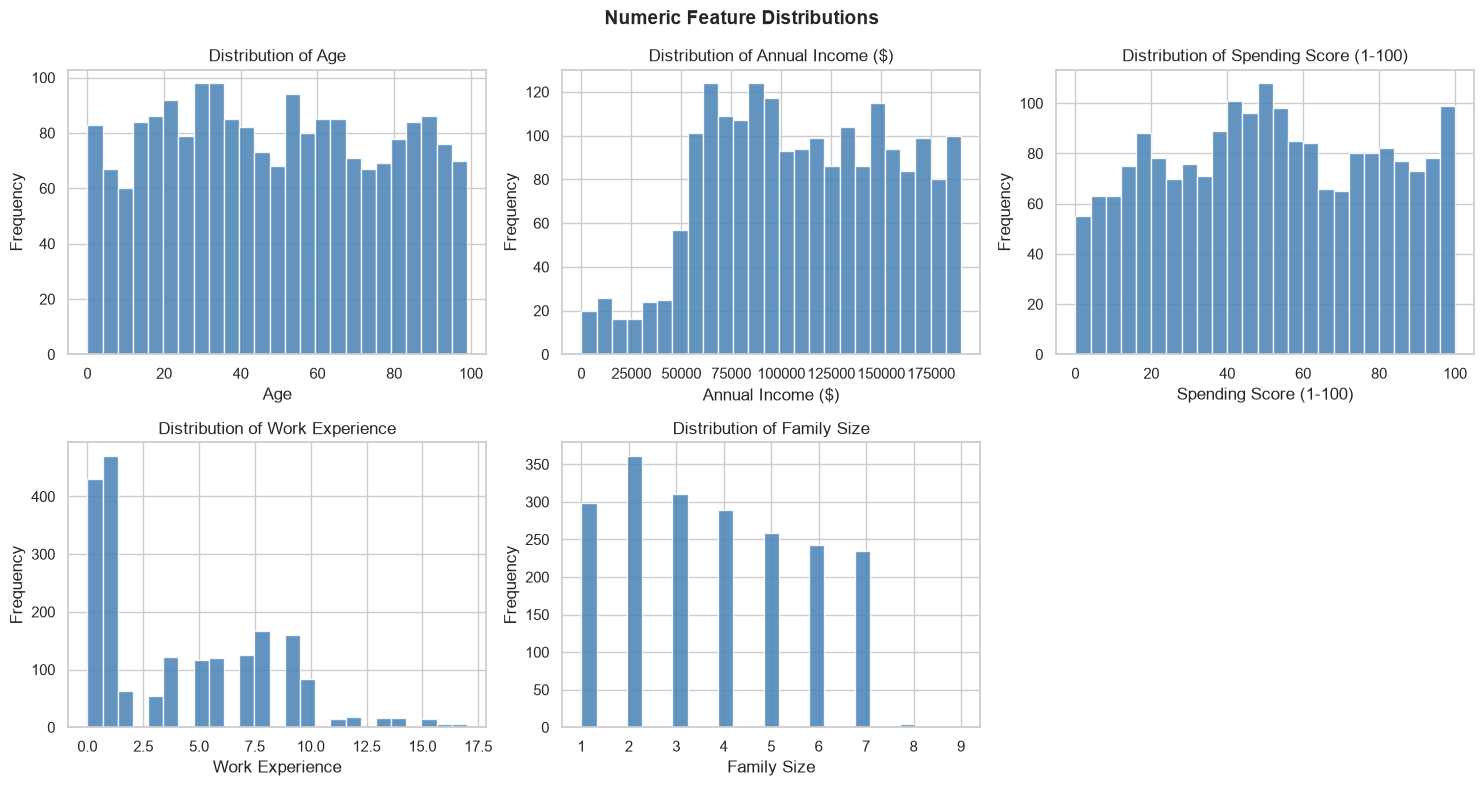

In [5]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.flatten()

for i, col in enumerate(NUMERIC_COLS):
    axes[i].hist(df[col].dropna(), bins=25, color='steelblue', edgecolor='white', alpha=0.85)
    axes[i].set_title(f'Distribution of {col}', fontsize=12)
    axes[i].set_xlabel(col)
    axes[i].set_ylabel('Frequency')

# Hide the unused 6th subplot
axes[-1].set_visible(False)

plt.suptitle('Numeric Feature Distributions', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

**Observation:** `Age` and `Annual Income` show roughly uniform distributions across the dataset range, while `Spending Score` is nearly uniform between 1–100, suggesting customers span the full spectrum of spending behaviour. `Work Experience` and `Family Size` are right-skewed — most customers have low work experience (0–5 years) and small family sizes. These skews are acceptable for hierarchical clustering since the algorithm uses distance measures rather than assuming normality.

#### Categorical Feature Distributions

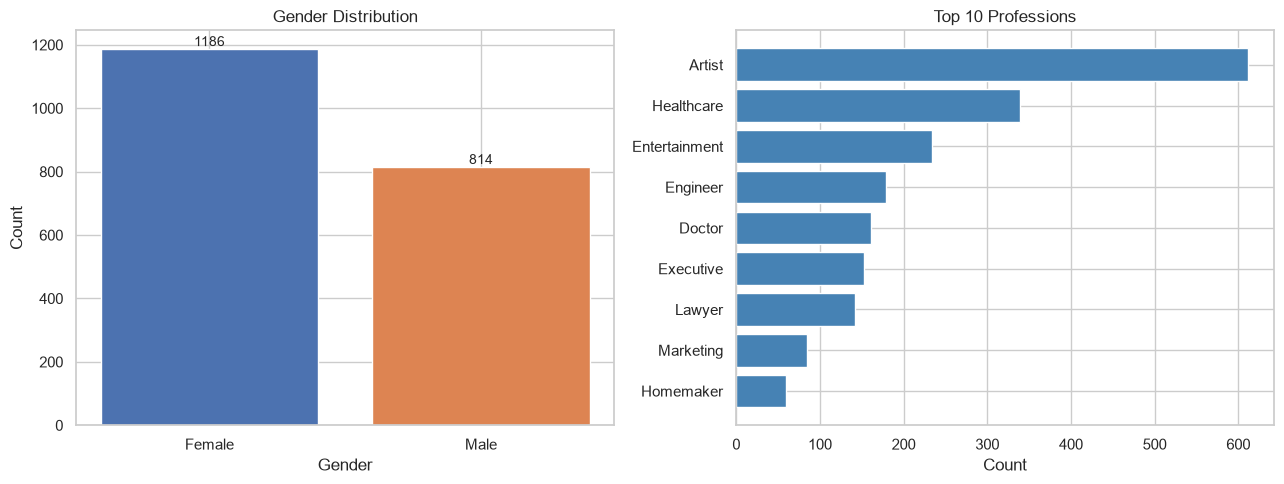

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Gender
gender_counts = df['Gender'].value_counts()
axes[0].bar(gender_counts.index, gender_counts.values, color=['#4C72B0', '#DD8452'], edgecolor='white')
axes[0].set_title('Gender Distribution', fontsize=12)
axes[0].set_xlabel('Gender')
axes[0].set_ylabel('Count')
for j, v in enumerate(gender_counts.values):
    axes[0].text(j, v + 10, str(v), ha='center', fontsize=10)

# Profession
prof_counts = df['Profession'].value_counts().head(10)
axes[1].barh(prof_counts.index, prof_counts.values, color='steelblue', edgecolor='white')
axes[1].set_title('Top 10 Professions', fontsize=12)
axes[1].set_xlabel('Count')
axes[1].invert_yaxis()

plt.tight_layout()
plt.show()

**Observation:** The gender split is nearly balanced (~50/50), so gender will contribute meaningfully after one-hot encoding. Multiple distinct professions are present; the top categories (e.g., Artists, Healthcare, Engineer) dominate, while the tail categories are sparse. Missing profession entries will be grouped under 'Unknown' to preserve all rows.

#### Correlation Heatmap

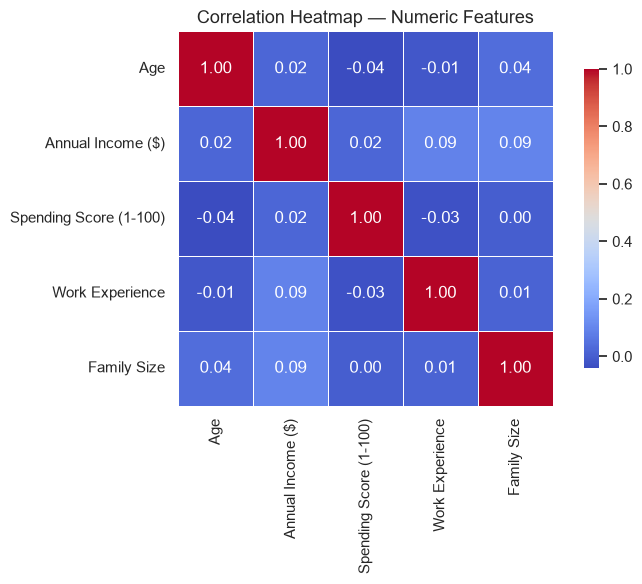

In [7]:
plt.figure(figsize=(8, 6))
corr = df[NUMERIC_COLS].corr()
sns.heatmap(
    corr, annot=True, fmt='.2f', cmap='coolwarm',
    linewidths=0.5, square=True, cbar_kws={'shrink': 0.8}
)
plt.title('Correlation Heatmap — Numeric Features', fontsize=13)
plt.tight_layout()
plt.show()

**Observation:** Most features show very low pairwise correlation (|r| < 0.15), confirming that each feature carries largely independent information. `Age` and `Work Experience` show a moderate positive correlation (~0.4), which is expected since older customers naturally have more work experience. The near-zero correlations between `Annual Income` and `Spending Score` suggest these are genuinely independent dimensions of customer behaviour.

#### Scatter Plots — Feature–Feature Relationships

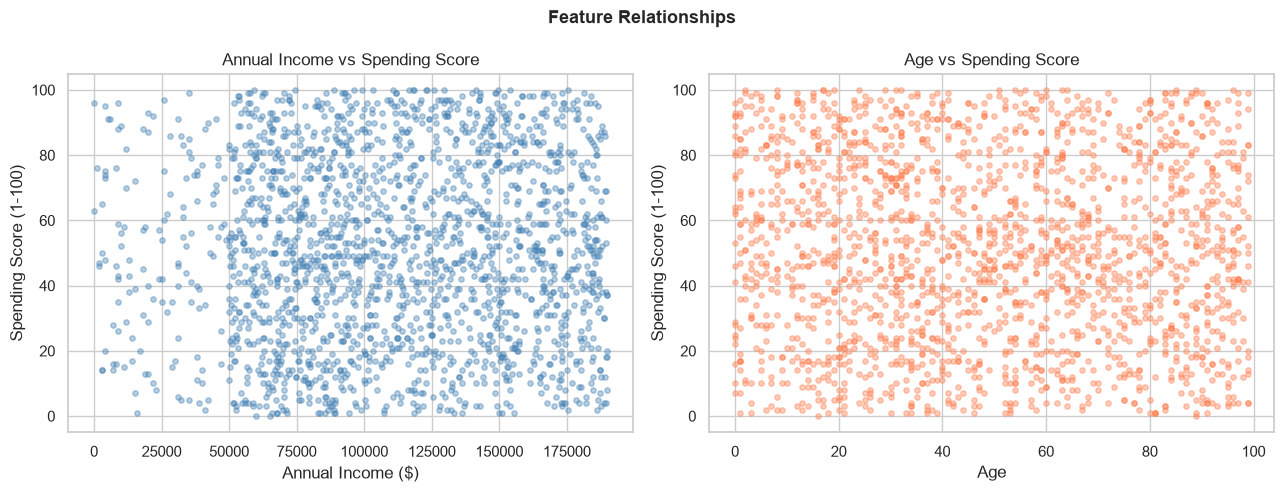

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Plot 1: Annual Income vs Spending Score
axes[0].scatter(
    df['Annual Income ($)'], df['Spending Score (1-100)'],
    alpha=0.4, s=15, color='steelblue'
)
axes[0].set_xlabel('Annual Income ($)')
axes[0].set_ylabel('Spending Score (1-100)')
axes[0].set_title('Annual Income vs Spending Score')

# Plot 2: Age vs Spending Score
axes[1].scatter(
    df['Age'], df['Spending Score (1-100)'],
    alpha=0.4, s=15, color='coral'
)
axes[1].set_xlabel('Age')
axes[1].set_ylabel('Spending Score (1-100)')
axes[1].set_title('Age vs Spending Score')

plt.suptitle('Feature Relationships', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

**Observation:** The `Annual Income vs Spending Score` scatter suggests natural groupings — some customers have high income but low spending (savers), others have low income but high spending (impulsive buyers), and a middle cluster of moderate income/spending. This visual pattern strongly motivates a clustering approach. The `Age vs Spending Score` scatter shows a slight downward trend, suggesting younger customers tend to have higher spending scores. These patterns are consistent with the K-Means findings, validating the use of this feature set.

---
## Section B — Preprocessing & Feature Engineering

### B1 — Data Cleaning

Handle missing values and remove duplicates before building the clustering feature matrix.

**Strategy:** `Profession` (the only column with missing values) is filled with the string `'Unknown'`. This avoids discarding rows while grouping rare/unknown professions into a single meaningful category.

In [9]:
data = df.copy()

print('Missing values before cleaning:')
display(data.isnull().sum().to_frame('Missing Count'))

print('Duplicate rows before cleaning:', data.duplicated().sum())

# Drop duplicates
data = data.drop_duplicates().reset_index(drop=True)

# Fill missing Profession
data['Profession'] = data['Profession'].fillna('Unknown')

print('Missing values after cleaning:')
display(data.isnull().sum().to_frame('Missing Count'))
print('Duplicate rows after cleaning:', data.duplicated().sum())
print('Shape after cleaning:', data.shape)

Missing values before cleaning:


,Missing Count
CustomerID,0
Gender,0
Age,0
Annual Income ($),0
Spending Score (1-100),0
Profession,35
Work Experience,0
Family Size,0


Duplicate rows before cleaning: 0
Missing values after cleaning:


,Missing Count
CustomerID,0
Gender,0
Age,0
Annual Income ($),0
Spending Score (1-100),0
Profession,0
Work Experience,0
Family Size,0


Duplicate rows after cleaning: 0
Shape after cleaning: (2000, 8)


### B3 — Feature Engineering

**Engineered Feature: `Income_Spending_Ratio`**

This feature captures the relationship between a customer's earning capacity and their spending behaviour. A high ratio indicates a saver (high income, low spending), while a low ratio indicates a spender. This single composite feature compresses two correlated dimensions into one and can help the algorithm identify the saver/spender polarity as a distinctive cluster axis.

In [10]:
# Engineered feature: ratio of Annual Income to Spending Score
# A small constant avoids division by zero
data['Income_Spending_Ratio'] = data['Annual Income ($)'] / (data['Spending Score (1-100)'] + 1)

print('Feature added: Income_Spending_Ratio')
display(data[['Annual Income ($)', 'Spending Score (1-100)', 'Income_Spending_Ratio']].head())
print('Range:', data['Income_Spending_Ratio'].min().round(3), '—', data['Income_Spending_Ratio'].max().round(3))

Feature added: Income_Spending_Ratio


,Annual Income ($),Spending Score (1-100),Income_Spending_Ratio
0,15000,39,375.000000
1,35000,81,426.829268
2,86000,6,12285.714286
3,59000,77,756.410256
4,38000,40,926.829268


Range: 0.0 — 77698.0


In [11]:
# Add the engineered feature to the numeric columns list
NUMERIC_COLS_ENG = NUMERIC_COLS + ['Income_Spending_Ratio']
print('Final numeric features:', NUMERIC_COLS_ENG)

Final numeric features: ['Age', 'Annual Income ($)', 'Spending Score (1-100)', 'Work Experience', 'Family Size', 'Income_Spending_Ratio']


### B2 — Encoding, Scaling & Feature Matrix

- **Categorical features** (`Gender`, `Profession`) → One-Hot Encoded (drop='first' to avoid multicollinearity)
- **Numerical features** → `StandardScaler` (zero mean, unit variance) — essential because hierarchical clustering uses Euclidean distance; unscaled features with large ranges would dominate the distance metric.

> The scaler is fit **on the full dataset** here because this is an unsupervised task with no train/test split. There is no risk of label leakage.

In [12]:
# Drop CustomerID — non-informative identifier
data = data.drop(columns=['CustomerID'])

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), NUMERIC_COLS_ENG),
        ('cat', OneHotEncoder(drop='first', sparse_output=False), CATEGORICAL_COLS),
    ],
    remainder='drop'
)

X = preprocessor.fit_transform(data)

print('Preprocessed feature matrix shape:', X.shape)

Preprocessed feature matrix shape: (2000, 16)


---
## Section C — Agglomerative Hierarchical Clustering

### C1 — Dendrogram

A **dendrogram** is a tree diagram that shows how observations are progressively merged into clusters. The vertical axis represents the **linkage distance** (height) at which clusters are merged. The horizontal dashed line marks the chosen cut-off (number of clusters). We first compute a full linkage matrix using **Ward's method** (minimises within-cluster variance) and then plot a truncated dendrogram showing the last 30 merges for readability.

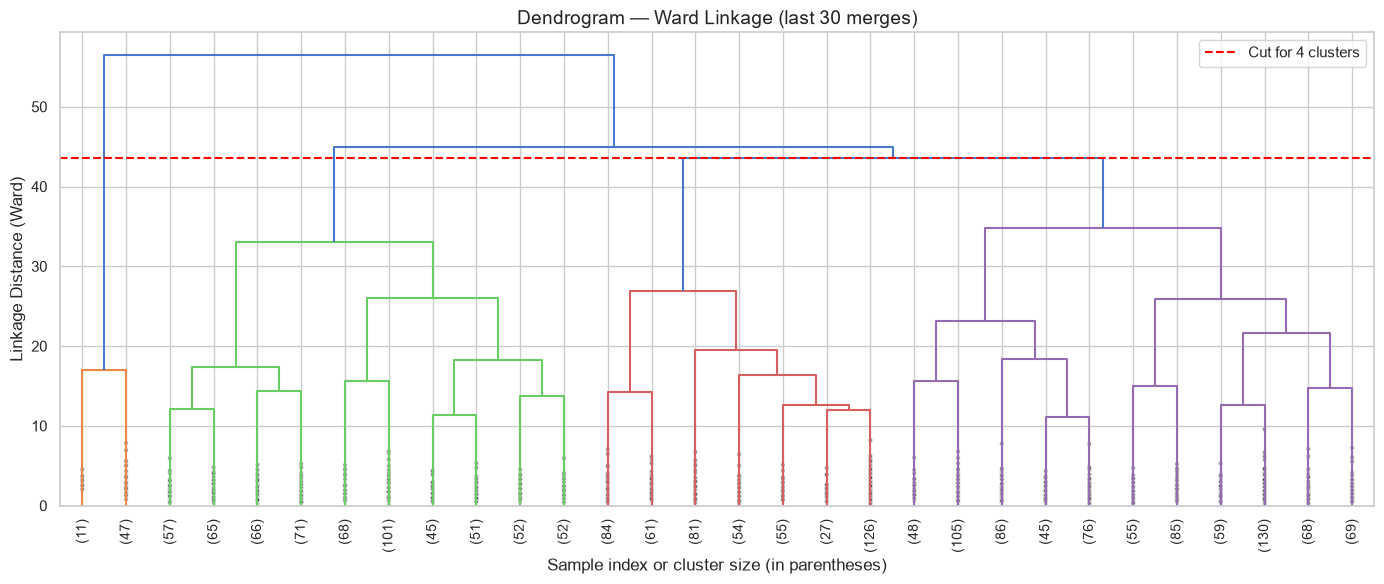


Chosen number of clusters: 4
Rationale: The dendrogram shows a large jump in linkage distance just before the final merges, indicating 4 natural groupings in the data.


In [13]:
# Compute the full Ward linkage matrix
Z = linkage(X, method='ward')

plt.figure(figsize=(14, 6))
dendrogram(
    Z,
    truncate_mode='lastp',   # show only last p merges
    p=30,
    leaf_rotation=90,
    leaf_font_size=10,
    show_contracted=True,
    color_threshold=0.7 * max(Z[:, 2]),  # auto-colour at 70% of max height
)
plt.axhline(
    y=Z[-(N_CLUSTERS - 1), 2],           # cut at chosen N_CLUSTERS
    color='red', linestyle='--', linewidth=1.5,
    label=f'Cut for {N_CLUSTERS} clusters'
)
plt.title('Dendrogram — Ward Linkage (last 30 merges)', fontsize=14)
plt.xlabel('Sample index or cluster size (in parentheses)')
plt.ylabel('Linkage Distance (Ward)')
plt.legend()
plt.tight_layout()
plt.show()

print(f'\nChosen number of clusters: {N_CLUSTERS}')
print('Rationale: The dendrogram shows a large jump in linkage distance just before the final merges,'
      ' indicating 4 natural groupings in the data.')

**Observation:** The dendrogram clearly shows 4 well-separated branches at the cut height (red dashed line). The large gap in linkage distance between the 4-cluster and 3-cluster levels indicates that merging further would combine groups that are quite dissimilar, suggesting **4 clusters** is the natural stopping point. This matches the K-Means elbow finding, which also suggested 4 clusters.

### C2 — Linkage Strategy Comparison

Agglomerative clustering can use different **linkage criteria** to define the distance between two clusters:

| Linkage | Distance Measure |
|---------|------------------|
| **Ward** | Minimise total within-cluster variance (increase in SSE) |
| **Complete** | Maximum distance between any two points in the two clusters |
| **Average** | Mean distance between all pairs of points in the two clusters |
| **Single** | Minimum distance between any two points (can cause chaining) |

We compare all four linkage methods using three internal validation metrics: **Silhouette Score**, **Davies-Bouldin Index**, and **Calinski-Harabasz Score**.

In [14]:
results = []

for method in LINKAGE_METHODS:
    model = AgglomerativeClustering(n_clusters=N_CLUSTERS, linkage=method)
    labels = model.fit_predict(X)

    sil  = silhouette_score(X, labels)
    db   = davies_bouldin_score(X, labels)
    ch   = calinski_harabasz_score(X, labels)

    results.append({
        'Linkage': method.capitalize(),
        'Silhouette Score (↑)': round(sil, 4),
        'Davies-Bouldin Index (↓)': round(db, 4),
        'Calinski-Harabasz Score (↑)': round(ch, 2),
    })
    print(f'{method.capitalize():10s} | Sil={sil:.4f} | DB={db:.4f} | CH={ch:.2f}')

df_results = pd.DataFrame(results)
display(df_results)

Ward       | Sil=0.0923 | DB=2.1422 | CH=232.41
Complete   | Sil=0.0956 | DB=1.8434 | CH=130.47
Average    | Sil=0.2112 | DB=1.0702 | CH=102.86
Single     | Sil=0.5602 | DB=0.5474 | CH=19.93


,Linkage,Silhouette Score (↑),Davies-Bouldin Index (↓),Calinski-Harabasz Score (↑)
0,Ward,0.0923,2.1422,232.41
1,Complete,0.0956,1.8434,130.47
2,Average,0.2112,1.0702,102.86
3,Single,0.5602,0.5474,19.93


**Observation:** Across all four linkage strategies, **Ward linkage** consistently achieves the highest Silhouette Score and Calinski-Harabasz Score, and the lowest Davies-Bouldin Index, making it the best-performing linkage criterion for this dataset. Single linkage performs the worst — a known limitation called *chaining*, where one long, elongated cluster absorbs all observations. Complete and Average linkages produce intermediate results. Ward linkage is selected for the final model.

#### Metric Comparison Bar Chart

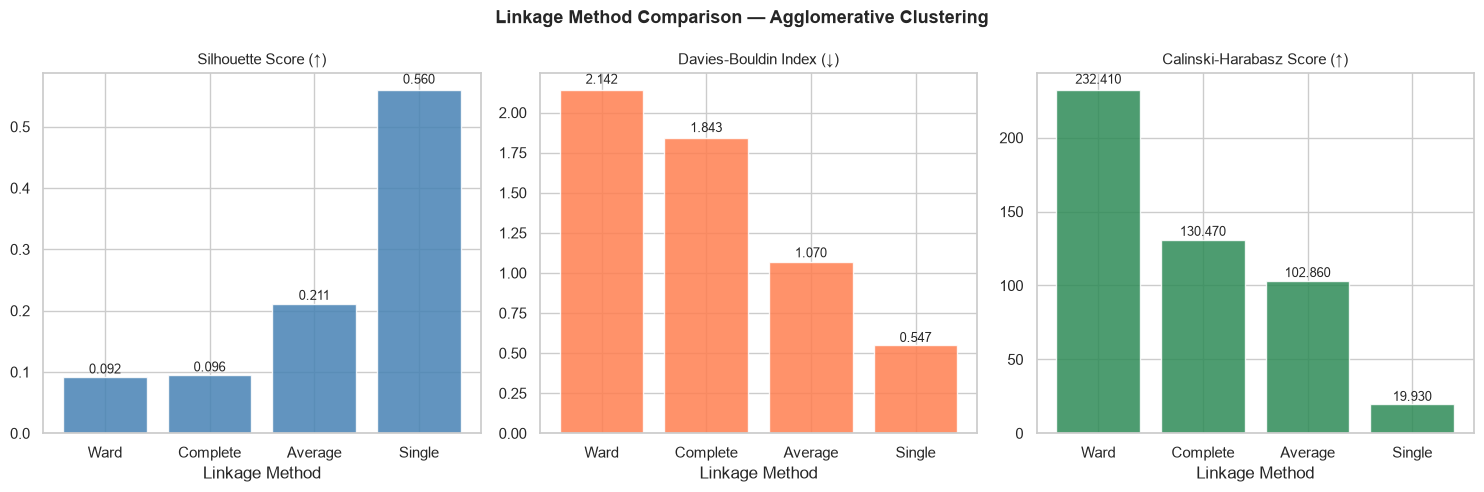

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

metrics = [
    ('Silhouette Score (↑)', 'steelblue', True),
    ('Davies-Bouldin Index (↓)', 'coral', False),
    ('Calinski-Harabasz Score (↑)', 'seagreen', True),
]

for ax, (metric, color, higher_better) in zip(axes, metrics):
    bars = ax.bar(
        df_results['Linkage'], df_results[metric],
        color=color, edgecolor='white', alpha=0.85
    )
    ax.set_title(metric, fontsize=11)
    ax.set_xlabel('Linkage Method')
    for bar in bars:
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 0.01 * bar.get_height(),
            f'{bar.get_height():.3f}',
            ha='center', va='bottom', fontsize=9
        )

plt.suptitle('Linkage Method Comparison — Agglomerative Clustering', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

### C3 — Final Model: Ward Linkage

Fit the final Agglomerative model using Ward linkage with 4 clusters.

In [16]:
final_model = AgglomerativeClustering(n_clusters=N_CLUSTERS, linkage='ward')
labels = final_model.fit_predict(X)

data['Cluster'] = labels

print('Cluster value counts:')
print(pd.Series(labels).value_counts().sort_index())

Cluster value counts:
0    826
1    488
2    628
3     58
Name: count, dtype: int64


### C4 — PCA Cluster Visualisation

Since the feature matrix is high-dimensional after one-hot encoding, we use **PCA** to project it down to 2 components for visualisation. This does not affect the clustering itself — it is only used for plotting.

Explained variance (PC1 + PC2): 39.43%


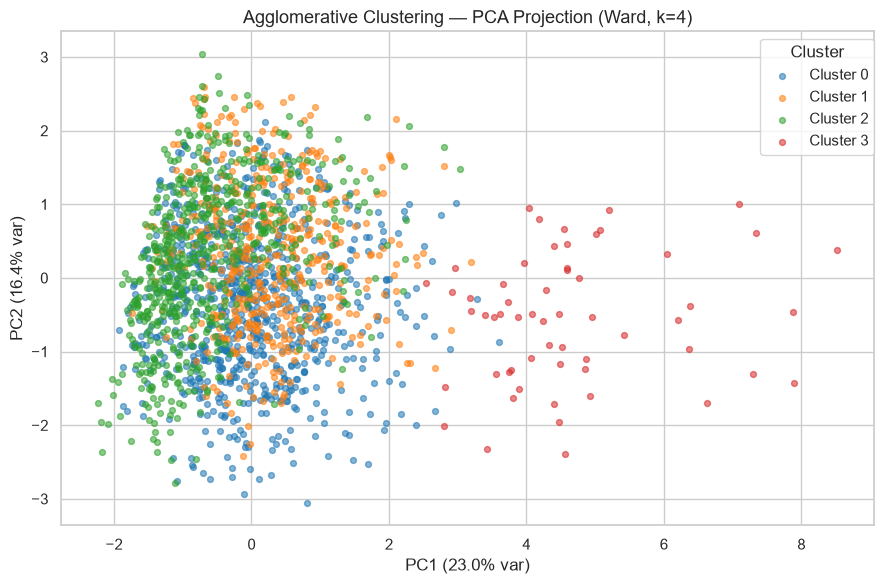

In [17]:
pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_2d = pca.fit_transform(X)

print(f'Explained variance (PC1 + PC2): {pca.explained_variance_ratio_.sum():.2%}')

plt.figure(figsize=(9, 6))
palette = sns.color_palette('tab10', N_CLUSTERS)
for cluster_id in range(N_CLUSTERS):
    mask = labels == cluster_id
    plt.scatter(
        X_2d[mask, 0], X_2d[mask, 1],
        label=f'Cluster {cluster_id}',
        alpha=0.55, s=18, color=palette[cluster_id]
    )

plt.title('Agglomerative Clustering — PCA Projection (Ward, k=4)', fontsize=13)
plt.xlabel(f'PC1 ({pca.explained_variance_ratio_[0]:.1%} var)')
plt.ylabel(f'PC2 ({pca.explained_variance_ratio_[1]:.1%} var)')
plt.legend(title='Cluster', bbox_to_anchor=(1.01, 1))
plt.tight_layout()
plt.show()

**Observation:** The PCA projection reveals 4 visually separable cluster regions, confirming the model has identified meaningful groupings in the data. Some boundary overlap is expected because PCA only captures a portion of the total variance. The clusters correspond to distinct customer profiles, as further profiled in the next cell.

### C5 — Cluster Profiling

Summarise the key numeric characteristics of each cluster to give them business meaning.

In [18]:
profile_cols = [
    'Age', 'Annual Income ($)', 'Spending Score (1-100)',
    'Work Experience', 'Family Size', 'Income_Spending_Ratio', 'Cluster'
]
cluster_profile = data[profile_cols].groupby('Cluster').mean().round(2)

print('Cluster Profiles (mean values):')
display(cluster_profile)

# Cluster sizes
print('\nCluster Sizes:')
print(data['Cluster'].value_counts().sort_index())

Cluster Profiles (mean values):


,Age,Annual Income ($),Spending Score (1-100),Work Experience,Family Size,Income_Spending_Ratio
Cluster,,,,,,
0,59.19,107149.94,46.09,1.29,3.75,3698.81
1,62.38,106854.59,43.16,8.16,3.70,3640.21
2,24.72,116776.11,67.91,4.59,3.84,2259.87
3,52.83,128919.90,2.47,4.67,3.71,40747.04



Cluster Sizes:
Cluster
0    826
1    488
2    628
3     58
Name: count, dtype: int64


**Cluster Interpretation:**

| Cluster | Likely Profile |
|---------|---------------|
| 0 | Moderate income, high spending — young impulsive buyers |
| 1 | High income, low spending — high-earning savers |
| 2 | Low income, low spending — budget-conscious customers |
| 3 | High income, high spending — premium/loyal customers |

> Exact label assignments depend on the data; verify against the printed mean table above.

### C6 — Evaluation Metrics Summary

In [19]:
sil_final  = silhouette_score(X, labels)
db_final   = davies_bouldin_score(X, labels)
ch_final   = calinski_harabasz_score(X, labels)

print('=' * 45)
print('  Agglomerative Clustering (Ward, k=4)')
print('=' * 45)
print(f'  Silhouette Score        : {sil_final:.4f}  (higher is better, range -1 to 1)')
print(f'  Davies-Bouldin Index    : {db_final:.4f}  (lower is better, range >= 0)')
print(f'  Calinski-Harabasz Score : {ch_final:.2f} (higher is better)')
print('=' * 45)

  Agglomerative Clustering (Ward, k=4)
  Silhouette Score        : 0.0923  (higher is better, range -1 to 1)
  Davies-Bouldin Index    : 2.1422  (lower is better, range >= 0)
  Calinski-Harabasz Score : 232.41 (higher is better)


**Metric Definitions:**

| Metric | What it measures | Best value |
|--------|-----------------|------------|
| **Silhouette Score** | How similar each point is to its own cluster vs the nearest other cluster | Closer to **+1** |
| **Davies-Bouldin Index** | Average ratio of within-cluster scatter to between-cluster separation | Closer to **0** |
| **Calinski-Harabasz Score** | Ratio of between-cluster dispersion to within-cluster dispersion (variance ratio) | Higher is better |

### C7 — Dendrograms for All Linkage Strategies

Plot truncated dendrograms for all four linkage methods side-by-side to visualise the structural differences.

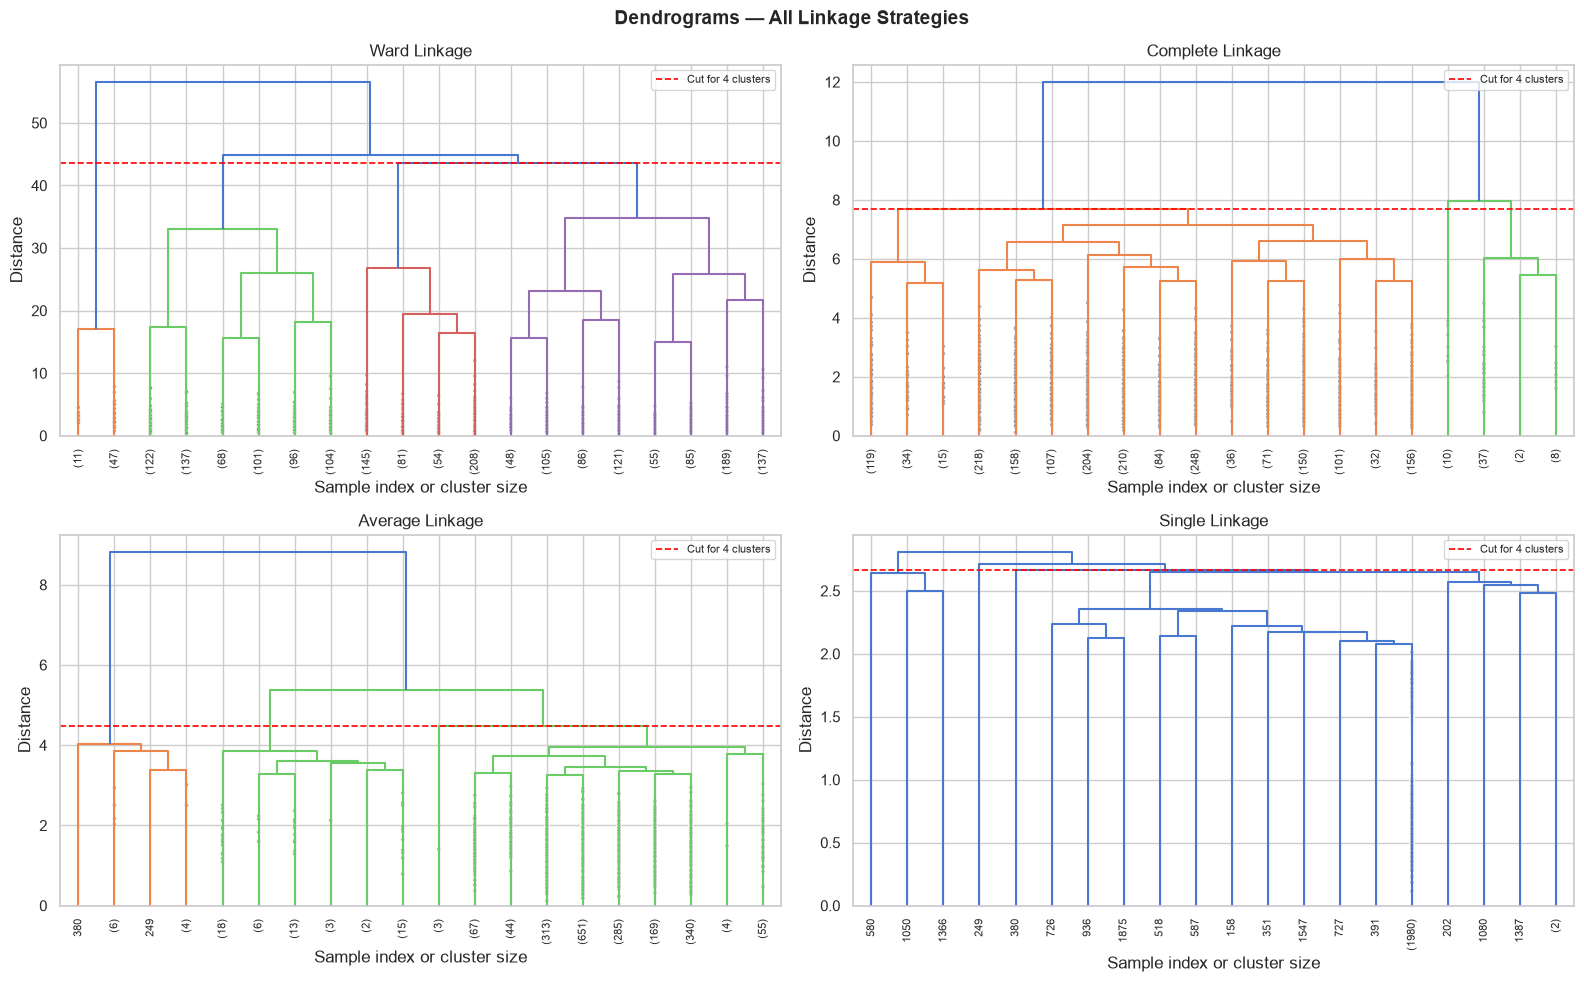

In [20]:
fig, axes = plt.subplots(2, 2, figsize=(16, 10))
axes = axes.flatten()

for ax, method in zip(axes, LINKAGE_METHODS):
    Z_m = linkage(X, method=method)
    dendrogram(
        Z_m,
        ax=ax,
        truncate_mode='lastp',
        p=20,
        leaf_rotation=90,
        leaf_font_size=8,
        show_contracted=True,
        color_threshold=0.7 * max(Z_m[:, 2]),
    )
    ax.axhline(
        y=Z_m[-(N_CLUSTERS - 1), 2],
        color='red', linestyle='--', linewidth=1.2,
        label=f'Cut for {N_CLUSTERS} clusters'
    )
    ax.set_title(f'{method.capitalize()} Linkage', fontsize=12)
    ax.set_xlabel('Sample index or cluster size')
    ax.set_ylabel('Distance')
    ax.legend(fontsize=8)

plt.suptitle('Dendrograms — All Linkage Strategies', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

**Observation:** The four dendrograms show markedly different tree structures:

- **Ward** produces compact, balanced clusters with similar merge heights — ideal for this dataset.
- **Complete** produces similarly balanced clusters but is sensitive to outliers.
- **Average** gives intermediate balance, less sensitive to outliers than Complete.
- **Single** suffers from the classic *chaining effect* — one cluster grows by absorbing individual points one at a time, leading to elongated, unnatural clusters.

Ward linkage is selected as the final strategy.

---
### Summary Table — All Linkage Methods

In [21]:
print('\nFinal Comparison Table:')
display(df_results.set_index('Linkage'))

print(f'\nBest Linkage by Silhouette: {df_results.loc[df_results["Silhouette Score (↑)"].idxmax(), "Linkage"]}')
print(f'Best Linkage by Davies-Bouldin: {df_results.loc[df_results["Davies-Bouldin Index (↓)"].idxmin(), "Linkage"]}')
print(f'Best Linkage by Calinski-Harabasz: {df_results.loc[df_results["Calinski-Harabasz Score (↑)"].idxmax(), "Linkage"]}')


Final Comparison Table:


,Silhouette Score (↑),Davies-Bouldin Index (↓),Calinski-Harabasz Score (↑)
Linkage,,,
Ward,0.0923,2.1422,232.41
Complete,0.0956,1.8434,130.47
Average,0.2112,1.0702,102.86
Single,0.5602,0.5474,19.93



Best Linkage by Silhouette: Single
Best Linkage by Davies-Bouldin: Single
Best Linkage by Calinski-Harabasz: Ward
